# BirdCLEF 2026 - data exploration and preparation
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DPI3/BridCLEF-team-buzby/blob/main/birdclef_draft_01.ipynb)

1. Audio file metadata (durations, sample rates) and the short-clip filter
2. Label tables and dataset overview
3. Taxonomy and name consistency
4. Training clip labels (class balance, ratings)
5. Soundscape labels
6. Example recordings (player, waveform, spectrograms)

**Part 2 - data preparation for training** (needs TensorFlow; a GPU is recommended)

7. Label targets (model outputs)
8. Frozen Perch v2 encoder and file selection
9. Embedding export (model inputs)
10. Train / validation / test split
11. Data loaders
12. Read-back check of the prepared data

Run the cells from top to bottom. Settings (e.g. the short-clip cutoff) are in the imports cell.

## 0. Data download

The cell below downloads the competition data from Kaggle, but only if it is not already in the `data/` folder. Complete these steps once before running it.

**1. Verify your Kaggle account**
1. Sign in (or create an account) at [kaggle.com](https://www.kaggle.com).
2. Go to **Settings → Phone verification, Identity verification** and verify yourself. Kaggle blocks competition data downloads for unverified accounts.

**2. Accept the competition rules**
1. Open the [BirdCLEF 2026 competition](https://www.kaggle.com/competitions/birdclef-2026).
2. Click **Join Competition** / **I Understand and Accept**.

**3. Create a Kaggle API token**
1. Go to **Settings → API** on kaggle.com and create a new token (it starts with `KGAT_`).
2. Copy it right away - Kaggle shows it only once. Never share it or commit it to git.

**4. Make the token available to the notebook**
The token must be stored under the name `KAGGLE_API_TOKEN`. Use one of these options:

**Option A - Colab secrets (when running in Google Colab)**
1. Click the key icon (**Secrets**) in the left sidebar.
2. Add a new secret named `KAGGLE_API_TOKEN` with your token as the value.
3. Switch on **Notebook access** for it.

**Option B - `.env` file (local, VS Code, or Colab)**
1. Copy `.env.example` to `.env` and set `KAGGLE_API_TOKEN=your_token_here`.
2. Running in Colab: upload the `.env` file to the Colab working directory (**Files** panel → upload, usually `/content`). It is lost when the session ends, so upload it again each session.

**5. Run the cell**
Run the next cell. It downloads and extracts the data (~16 GB, so make sure there is enough free disk space). If the data is already there, it only prints the path.

In [5]:
import os
import subprocess
import sys
from pathlib import Path

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, display
from tinytag import TinyTag

# Settings
MIN_DURATION_SECONDS = 2.0  # Training clips shorter than this are dropped.
WINDOW_SECONDS = 5  # Soundscape labels cover 5-second intervals.
N_FFT = 2048  # Spectrogram settings for the example plots.
HOP_LENGTH = 512
N_MELS = 128
PLAYER_MAX_SECONDS = 60  # Longer recordings are cut in the audio player to keep the notebook small.

In [9]:
COMPETITION = "birdclef-2026"
KAGGLE_TOKEN = "KAGGLE_API_TOKEN"  # name of the Colab secret / .env variable
DATA_ROOT = Path.cwd() / "data"  # git-ignored; kagglehub stores its cache here

# Files and folders that must exist for the data to count as complete
REQUIRED = [
    "train.csv",
    "taxonomy.csv",
    "train_soundscapes_labels.csv",
    "train_audio",
    "train_soundscapes",
]

In [14]:
def is_complete(folder):
    return all((folder / name).exists() for name in REQUIRED)


def find_local_data():
    """Return the folder holding the competition files, or None."""
    for train_csv in DATA_ROOT.rglob("train.csv"):
        if is_complete(train_csv.parent):
            return train_csv.parent
    return None


def load_from_colab_secrets():
    """Read the token from Colab Secrets; return False outside Colab."""
    try:
        from google.colab import userdata
    except ImportError:
        return False

    try:
        value = userdata.get(KAGGLE_TOKEN)
    except Exception:  # secret not defined or notebook access off
        return True
    if value:
        os.environ[KAGGLE_TOKEN] = value.strip()
    return True


def load_from_env_file():
    """Read the token from the nearest .env file (current folder or a parent)."""
    for folder in [Path.cwd(), *Path.cwd().parents]:
        env_file = folder / ".env"
        if not env_file.is_file():
            continue
        for line in env_file.read_text(encoding="utf-8").splitlines():
            line = line.strip()
            if not line or line.startswith("#") or "=" not in line:
                continue
            key, value = line.split("=", 1)
            key = key.strip().removeprefix("export ").strip()
            value = value.strip().strip("\"'")
            if key == KAGGLE_TOKEN and value:
                os.environ[KAGGLE_TOKEN] = value
        print(f"Loaded .env from {env_file}")
        return True
    return False


DATA_DIR = find_local_data()

if DATA_DIR:
    print(f"Data already available: {DATA_DIR}")
else:
    print(f"Data not found in {DATA_ROOT}, downloading from Kaggle...")

    # Token: 1. Colab secrets, 2. .env file
    load_from_colab_secrets()
    if not os.environ.get(KAGGLE_TOKEN):
        load_from_env_file()
    if not os.environ.get(KAGGLE_TOKEN):
        raise EnvironmentError(
            f"{KAGGLE_TOKEN} not found. Add it as a Colab secret (notebook "
            f"access on) or to a .env file. Working directory: {Path.cwd()}"
        )

    # Keep the kagglehub cache inside the repo (must be set before the import).
    os.environ["KAGGLEHUB_CACHE"] = str(DATA_ROOT)

    try:
        import kagglehub
    except ImportError:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", "kagglehub"],
            check=True,
        )
        import kagglehub

    # Authenticate explicitly with the token
    from kagglehub.config import set_kaggle_api_token

    set_kaggle_api_token(os.environ[KAGGLE_TOKEN])

    # Fails here with a clear error if the token is rejected.
    print("Authenticated as:", kagglehub.whoami()["username"])

    # The competition rules must be accepted on kaggle.com (same account).
    DATA_DIR = Path(kagglehub.competition_download(COMPETITION))
    print("Path to competition files:", DATA_DIR)

    if not is_complete(DATA_DIR):
        missing = [n for n in REQUIRED if not (DATA_DIR / n).exists()]
        raise FileNotFoundError(f"Download finished but missing: {missing}")

Data not found in /Users/dpi/Documents/egyetem/9-felev/Deep learning a gyakorlatban Python es Lua/nagyhf/BridCLEF-team-buzby/data, downloading from Kaggle...
Kaggle credentials set.
Kaggle credentials successfully validated.
Authenticated as: dpiet42
Download already complete (16073652829 bytes).
Extracting files...
Path to competition files: /Users/dpi/Documents/egyetem/9-felev/Deep learning a gyakorlatban Python es Lua/nagyhf/BridCLEF-team-buzby/data/competitions/birdclef-2026


## 1. Audio file metadata
Reads duration, channels, sample rate and bitrate from each file header (no decoding).
The first run takes a while; the results are cached as CSV files in the data folder.
Filenames are stored relative to their audio folder (`species/file.ogg`, as in `train.csv`),
so the cache works on any machine.

In [15]:
train_audio_dir = DATA_DIR / "train_audio"
train_soundscapes_dir = DATA_DIR / "train_soundscapes"
train_audio_metadata_csv = DATA_DIR / "train_audio_metadata.csv"
train_soundscapes_metadata_csv = DATA_DIR / "train_soundscapes_metadata.csv"

# All audio files, relative to their folder: "species/file.ogg" and "file.ogg"
train_audio_files = sorted(p.relative_to(train_audio_dir).as_posix() for p in train_audio_dir.glob("*/*.ogg"))
train_soundscapes_files = sorted(p.relative_to(train_soundscapes_dir).as_posix() for p in train_soundscapes_dir.glob("*.ogg"))


def get_audio_metadata(audio_dir: Path, files: list[str], csv_output: Path | None = None) -> pd.DataFrame:
    """Read the header metadata of `files` (paths relative to `audio_dir`)."""
    rows = []
    for f in files:
        audio = TinyTag.get(audio_dir / f)
        rows.append({
            "filename": f,
            "duration": audio.duration,
            "channels": audio.channels,
            "sample_rate": audio.samplerate,
            "bitrate": audio.bitrate,
        })
    metadata_df = pd.DataFrame(rows)
    if csv_output:
        metadata_df.to_csv(csv_output, index=False)
    return metadata_df


def to_relative(path, n_parts: int) -> str:
    """Keep the last `n_parts` components of a (possibly absolute, Windows or POSIX) path."""
    return "/".join(str(path).replace("\\", "/").split("/")[-n_parts:])


def load_audio_metadata(csv_path: Path, audio_dir: Path, files: list[str], n_parts: int) -> pd.DataFrame:
    """Load cached metadata (converting old absolute paths), or compute and cache it."""
    if not csv_path.exists():
        return get_audio_metadata(audio_dir, files, csv_path)
    df = pd.read_csv(csv_path)
    relative = df["filename"].map(lambda p: to_relative(p, n_parts))
    if not relative.equals(df["filename"]):
        df["filename"] = relative
        df.to_csv(csv_path, index=False)  # Rewrite the cache with relative paths.
        print(f"Converted absolute paths to relative in {csv_path.name}")
    return df


train_audio_metadata_df = load_audio_metadata(
    train_audio_metadata_csv, train_audio_dir, train_audio_files, n_parts=2
).set_index("filename")
train_soundscapes_metadata_df = load_audio_metadata(
    train_soundscapes_metadata_csv, train_soundscapes_dir, train_soundscapes_files, n_parts=1
).set_index("filename")

display(train_audio_metadata_df.head())
display(train_soundscapes_metadata_df.head())

,duration,channels,sample_rate,bitrate
filename,,,,
1161364/iNat1114648.ogg,28.392000,1,32000,86.0
1161364/iNat1216197.ogg,18.024000,1,32000,86.0
1161364/iNat1264238.ogg,0.288000,1,32000,86.0
1161364/iNat547199.ogg,15.782875,1,32000,86.0
1161364/iNat556514.ogg,71.064000,1,32000,86.0


,duration,channels,sample_rate,bitrate
filename,,,,
BC2026_Train_0001_S08_20250606_030007.ogg,60.0,1,32000,72.0
BC2026_Train_0002_S08_20250607_030007.ogg,60.0,1,32000,72.0
BC2026_Train_0003_S08_20250607_070007.ogg,60.0,1,32000,72.0
BC2026_Train_0004_S08_20250607_070007.ogg,60.0,1,32000,72.0
BC2026_Train_0005_S08_20250607_070007.ogg,60.0,1,32000,72.0


In [16]:
# Sample rates, channels and durations
for name, df in [("Training clips", train_audio_metadata_df), ("Soundscapes", train_soundscapes_metadata_df)]:
    durations = df["duration"]
    print(f"{name}: {len(df):,} files")
    print(f"  sample rates: {sorted(df['sample_rate'].unique().tolist())}")
    print(f"  channels:     {sorted(df['channels'].unique().tolist())}")
    print(f"  duration (s): min {durations.min():.2f}, median {durations.median():.2f}, "
          f"max {durations.max():.2f}, {durations.nunique():,} distinct values")

Training clips: 35,549 files
  sample rates: [32000]
  channels:     [1]
  duration (s): min 0.01, median 21.00, max 6881.10, 16,596 distinct values
Soundscapes: 10,658 files
  sample rates: [32000]
  channels:     [1]
  duration (s): min 60.00, median 60.00, max 60.00, 1 distinct values


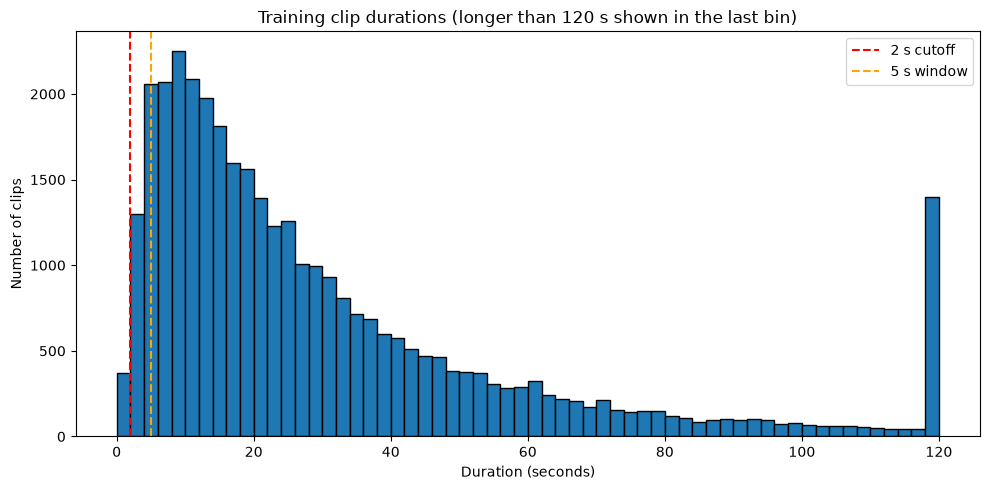

Clips longer than 120 s: 1,363


In [17]:
# Duration distribution of the training clips (all files, x-axis cut at 120 s)
DURATION_PLOT_LIMIT = 120
durations = train_audio_metadata_df["duration"]

plt.figure(figsize=(10, 5))
plt.hist(durations.clip(upper=DURATION_PLOT_LIMIT), bins=60, edgecolor="black")
plt.axvline(MIN_DURATION_SECONDS, color="red", linestyle="--", label=f"{MIN_DURATION_SECONDS:g} s cutoff")
plt.axvline(WINDOW_SECONDS, color="orange", linestyle="--", label=f"{WINDOW_SECONDS} s window")
plt.title(f"Training clip durations (longer than {DURATION_PLOT_LIMIT} s shown in the last bin)")
plt.xlabel("Duration (seconds)")
plt.ylabel("Number of clips")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Clips longer than {DURATION_PLOT_LIMIT} s: {(durations > DURATION_PLOT_LIMIT).sum():,}")

### Drop very short clips
Training clips shorter than `MIN_DURATION_SECONDS` are removed. `train_audio_files` keeps the
remaining clips and is used to filter `train.csv` below.

In [18]:
is_long_enough = train_audio_metadata_df["duration"] >= MIN_DURATION_SECONDS
train_audio_files = train_audio_metadata_df.index[is_long_enough].tolist()
print(f"Dropped {(~is_long_enough).sum():,} clips shorter than {MIN_DURATION_SECONDS:g} s; "
      f"{len(train_audio_files):,} remain.")

Dropped 370 clips shorter than 2 s; 35,179 remain.


## 2. Label tables
- `taxonomy.csv`: one row per species (class), with its names and animal class.
- `train.csv`: one row per training clip; `primary_label` is the species.
- `train_soundscapes_labels.csv`: species heard in each labeled 5-second soundscape interval.

In [19]:
taxonomy_df = pd.read_csv(DATA_DIR / "taxonomy.csv")
train_audio_label_df = pd.read_csv(DATA_DIR / "train.csv")
soundscapes_df = pd.read_csv(DATA_DIR / "train_soundscapes_labels.csv").drop_duplicates()

# Keep only the clips that passed the duration filter
rows_before = len(train_audio_label_df)
train_audio_label_df = train_audio_label_df[train_audio_label_df["filename"].isin(train_audio_files)]
print(f"train.csv: {rows_before:,} rows, {len(train_audio_label_df):,} after dropping short clips")

display(taxonomy_df.head())
display(train_audio_label_df.head())
display(soundscapes_df.head())

train.csv: 35,549 rows, 35,179 after dropping short clips


,primary_label,inat_taxon_id,scientific_name,common_name,class_name
0,1161364,1161364,Guyalna cuta,Guyalna cuta,Insecta
1,116570,116570,Caiman yacare,Southern Spectacled Caiman,Reptilia
2,1176823,1176823,Leptodactylus luctator,Wrestler Frog,Amphibia
3,1491113,1491113,Adenomera guarani,Guaraní leaf-litter frog,Amphibia
4,1595929,1595929,Lysapsus limellum,Uruguay Harlequin Frog,Amphibia


,primary_label,secondary_labels,type,latitude,longitude,scientific_name,common_name,class_name,inat_taxon_id,author,license,rating,url,filename,collection
0,1161364,[],[],-22.7562,-46.8666,Guyalna cuta,Guyalna cuta,Insecta,1161364,Lucas Barbosa,cc-by-nc,0.0,https://static.inaturalist.org/sounds/1216197....,1161364/iNat1216197.ogg,iNat
1,1161364,[],[],-22.7558,-46.8700,Guyalna cuta,Guyalna cuta,Insecta,1161364,Lucas Barbosa,cc-by-nc,0.0,https://static.inaturalist.org/sounds/1114648....,1161364/iNat1114648.ogg,iNat
2,1161364,[],[],-22.7547,-46.8728,Guyalna cuta,Guyalna cuta,Insecta,1161364,Lucas Barbosa,cc-by-nc,0.0,https://static.inaturalist.org/sounds/810195.m...,1161364/iNat810195.ogg,iNat
3,1161364,[],[],-22.7547,-46.8728,Guyalna cuta,Guyalna cuta,Insecta,1161364,Lucas Barbosa,cc-by-nc,0.0,https://static.inaturalist.org/sounds/818781.m...,1161364/iNat818781.ogg,iNat
4,1161364,[],[],-22.7426,-46.8985,Guyalna cuta,Guyalna cuta,Insecta,1161364,Lucas Barbosa,cc-by-nc,0.0,https://static.inaturalist.org/sounds/556514.m...,1161364/iNat556514.ogg,iNat


,filename,start,end,primary_label
0,BC2026_Train_0039_S22_20211231_201500.ogg,00:00:00,00:00:05,22961;23158;24321;517063;65380
1,BC2026_Train_0039_S22_20211231_201500.ogg,00:00:05,00:00:10,22961;23158;24321;517063;65380
2,BC2026_Train_0039_S22_20211231_201500.ogg,00:00:10,00:00:15,22961;23158;24321;517063;65380
3,BC2026_Train_0039_S22_20211231_201500.ogg,00:00:15,00:00:20,22961;23158;24321;517063;65380
4,BC2026_Train_0039_S22_20211231_201500.ogg,00:00:20,00:00:25,22961;23158;24321;517063;65380


In [20]:
# Dataset overview
overview = pd.Series({
    "Training clips (after the duration filter)": len(train_audio_label_df),
    "Soundscape files (all)": len(train_soundscapes_files),
    "Soundscape files with labels": soundscapes_df["filename"].nunique(),
    "Labeled soundscape intervals": len(soundscapes_df),
    "Taxonomy species": len(taxonomy_df),
}, name="Count")
display(overview.to_frame())

,Count
Training clips (after the duration filter),35179
Soundscape files (all),10658
Soundscape files with labels,66
Labeled soundscape intervals,739
Taxonomy species,234


## 3. Taxonomy
Checks that species identifiers and names are unique, and that the names used in `train.csv`
match the taxonomy.

In [21]:
assert taxonomy_df["primary_label"].is_unique, "Primary labels in taxonomy.csv are not unique."
assert taxonomy_df["scientific_name"].is_unique, "Scientific names in taxonomy.csv are not unique."
print(f"Taxonomy: {len(taxonomy_df)} species, identifiers and scientific names are unique.")

# Compare label-name combinations; the outer merge shows those that exist on only one side.
name_columns = ["primary_label", "scientific_name", "common_name", "class_name"]
comparison = taxonomy_df[name_columns].drop_duplicates().merge(
    train_audio_label_df[name_columns].drop_duplicates(),
    on=name_columns, how="outer", indicator=True,
)
side_counts = comparison["_merge"].value_counts()
print(f"Species in both tables:               {side_counts['both']}")
print(f"Only in taxonomy (no training clips): {side_counts['left_only']}")
print(f"Only in train.csv (name mismatch):    {side_counts['right_only']}")
if side_counts["right_only"] > 0:
    display(comparison[comparison["_merge"] == "right_only"])

taxonomy_df = taxonomy_df.set_index("primary_label")

Taxonomy: 234 species, identifiers and scientific names are unique.
Species in both tables:               206
Only in taxonomy (no training clips): 28
Only in train.csv (name mismatch):    0


## 4. Training clip labels
Species per animal class (taxonomy vs. training clips), recordings per species, and ratings.

In [22]:
assert train_audio_label_df["filename"].is_unique, "Filenames in train.csv are not unique."
train_audio_label_df = train_audio_label_df.set_index("filename")

# Species per animal class: how many have training clips?
species_per_class = pd.DataFrame({
    "in_taxonomy": taxonomy_df["class_name"].value_counts(),
    "with_training_clips": train_audio_label_df.drop_duplicates("primary_label")["class_name"].value_counts(),
}).fillna(0).astype(int)
species_per_class["without_training_clips"] = (
    species_per_class["in_taxonomy"] - species_per_class["with_training_clips"]
)
display(species_per_class.sort_values("in_taxonomy", ascending=False))

# Recordings per species
clips_per_species = train_audio_label_df["primary_label"].value_counts()
taxonomy_df["training_audio_files_count"] = clips_per_species.reindex(taxonomy_df.index, fill_value=0)

print("Species with the most and the fewest training clips:")
species_counts = train_audio_label_df.value_counts(["primary_label", "common_name", "class_name"])
display(pd.concat([species_counts.head(5), species_counts.tail(5)]).to_frame("clips"))

print("Training clips per species, by animal class:")
with_clips = taxonomy_df[taxonomy_df["training_audio_files_count"] > 0]
display(
    with_clips.groupby("class_name")["training_audio_files_count"]
    .agg(species="count", min="min", median="median", mean="mean", max="max")
    .round(1)
    .sort_values("species", ascending=False)
)

,in_taxonomy,with_training_clips,without_training_clips
class_name,,,
Aves,162,162,0
Amphibia,35,32,3
Insecta,28,3,25
Mammalia,8,8,0
Reptilia,1,1,0


Species with the most and the fewest training clips:


,,,clips
primary_label,common_name,class_name,
yeofly1,Yellow-olive Flatbill,Aves,493
banana,Bananaquit,Aves,491
soulap1,Southern Lapwing,Aves,491
fepowl,Ferruginous Pygmy Owl,Aves,490
bncfly,Brown-crested Flycatcher,Aves,488
116570,Southern Spectacled Caiman,Reptilia,1
209233,Feral Horse,Mammalia,1
23150,Central Dwarf Frog,Amphibia,1
23724,Waxy Monkey Tree Frog,Amphibia,1


Training clips per species, by animal class:


,species,min,median,mean,max
class_name,,,,,
Aves,162,3,166.0,212.7,493
Amphibia,32,1,7.0,13.5,59
Mammalia,8,1,7.5,11.2,37
Insecta,3,7,10.0,65.0,178
Reptilia,1,1,1.0,1.0,1


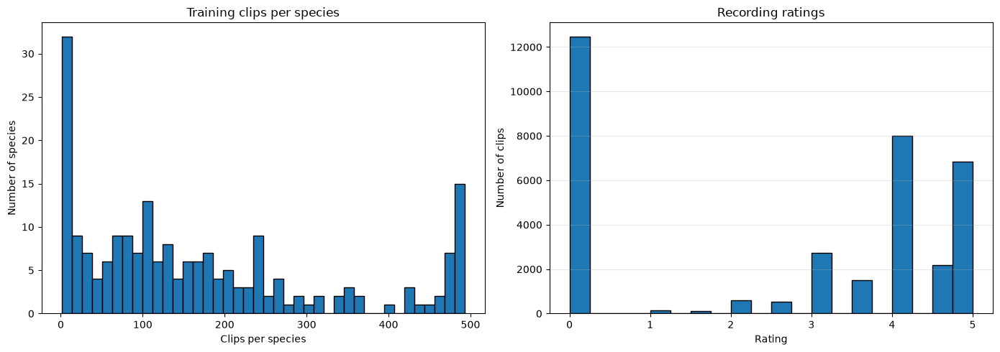

In [23]:
# Distributions: recordings per species and recording ratings
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(clips_per_species.values, bins=40, edgecolor="black")
axes[0].set_title("Training clips per species")
axes[0].set_xlabel("Clips per species")
axes[0].set_ylabel("Number of species")

ratings = pd.to_numeric(train_audio_label_df["rating"], errors="coerce")
axes[1].hist(ratings.dropna(), bins=20, edgecolor="black")
axes[1].set_title("Recording ratings")
axes[1].set_xlabel("Rating")
axes[1].set_ylabel("Number of clips")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Soundscape labels
Each row labels one 5-second interval of a 60-second soundscape with the species heard in it
(`;`-separated). Not every interval of a file is labeled.

In [24]:
def soundscape_labels_to_list(labels):
    """Convert a ';'-separated label string to a list of labels."""
    if pd.isna(labels):
        return []
    return [label.strip() for label in labels.split(";")]


soundscapes_df["labels"] = soundscapes_df["primary_label"].map(soundscape_labels_to_list)

# Labeled intervals per file (a fully labeled 60 s file has 12)
intervals_per_file = soundscapes_df["filename"].value_counts()
print(f"{len(intervals_per_file)} labeled soundscape files; labeled intervals per file: "
      f"min {intervals_per_file.min()}, median {intervals_per_file.median():g}, max {intervals_per_file.max()}")

if soundscapes_df.duplicated(subset=["filename", "start", "end"]).any():
    print("WARNING: some (filename, start, end) intervals appear in more than one row.")
else:
    print("Every (filename, start, end) interval appears once.")

# One row per (interval, species)
soundscape_species = (
    soundscapes_df[["filename", "labels"]]
    .explode("labels")
    .rename(columns={"labels": "label"})
    .dropna()
)
soundscape_species["class_name"] = soundscape_species["label"].map(taxonomy_df["class_name"])

taxonomy_df["soundscape_label_count"] = (
    soundscape_species["label"].value_counts().reindex(taxonomy_df.index, fill_value=0)
)
taxonomy_df["soundscape_file_count"] = (
    soundscape_species.groupby("label")["filename"].nunique().reindex(taxonomy_df.index, fill_value=0)
)

print("\nSoundscape coverage per animal class:")
display(
    soundscape_species.groupby("class_name")
    .agg(species=("label", "nunique"), files=("filename", "nunique"), labeled_intervals=("label", "size"))
    .sort_values("files", ascending=False)
)

only_in_soundscapes = taxonomy_df[
    (taxonomy_df["training_audio_files_count"] == 0) & (taxonomy_df["soundscape_label_count"] > 0)
]
print(f"Species with no training clips that appear in soundscapes: {len(only_in_soundscapes)}")
display(only_in_soundscapes[["common_name", "class_name", "soundscape_label_count", "soundscape_file_count"]])

66 labeled soundscape files; labeled intervals per file: min 2, median 12, max 12
Every (filename, start, end) interval appears once.

Soundscape coverage per animal class:


,species,files,labeled_intervals
class_name,,,
Amphibia,17,49,2087
Aves,28,25,412
Insecta,25,14,568
Mammalia,4,9,42
Reptilia,1,8,13


Species with no training clips that appear in soundscapes: 28


,common_name,class_name,soundscape_label_count,soundscape_file_count
primary_label,,,,
1491113,Guaraní leaf-litter frog,Amphibia,79,8
25073,Chiasmocleis mehelyi,Amphibia,12,1
47158son01,Insect sonotype01,Insecta,23,2
47158son02,Insect sonotype02,Insecta,7,1
47158son03,Insect sonotype03,Insecta,33,3
47158son04,Insect sonotype04,Insecta,17,3
47158son05,Insect sonotype05,Insecta,3,2
47158son06,Insect sonotype06,Insecta,18,2
47158son07,Insect sonotype07,Insecta,48,4


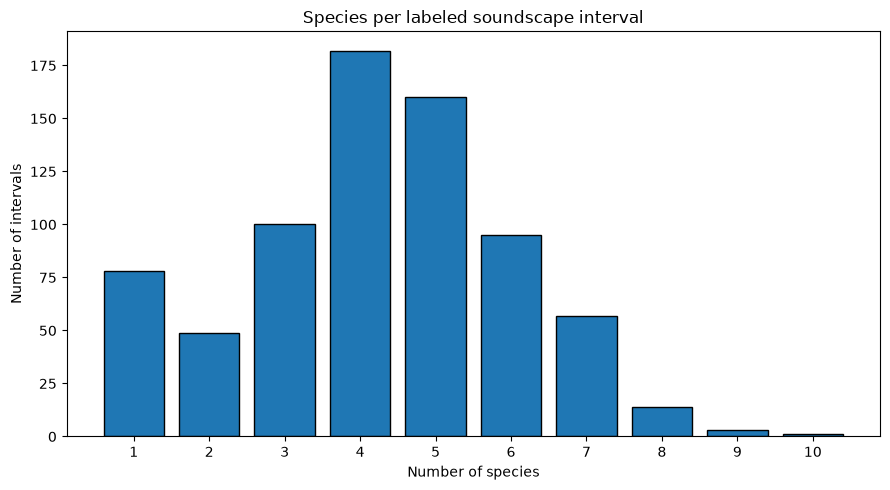

In [ ]:
# Number of species per labeled soundscape interval
species_per_interval = soundscapes_df["labels"].map(len).value_counts().sort_index()

plt.figure(figsize=(9, 5))
plt.bar(species_per_interval.index, species_per_interval.values, edgecolor="black")
plt.xticks(species_per_interval.index)
plt.title("Species per labeled soundscape interval")
plt.xlabel("Number of species")
plt.ylabel("Number of intervals")
plt.tight_layout()
plt.show()

## 6. Example recordings
Audio player, waveform, STFT spectrogram and mel spectrogram. Change the number in each cell
to look at a different recording.

In [ ]:
def plot_recording(y, sr, title, figsize=(14, 10)):
    """Plot the waveform, STFT spectrogram and mel spectrogram of a recording; return the axes."""
    stft_db = librosa.amplitude_to_db(
        np.abs(librosa.stft(y, n_fft=N_FFT, hop_length=HOP_LENGTH)), ref=np.max
    )
    mel_db = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS),
        ref=np.max,
    )
    fig, axes = plt.subplots(3, 1, figsize=figsize, sharex=True)

    librosa.display.waveshow(y, sr=sr, ax=axes[0])
    axes[0].set_title(f"Waveform - {title}")
    axes[0].set_ylabel("Amplitude")

    img = librosa.display.specshow(stft_db, sr=sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="hz", ax=axes[1])
    axes[1].set_title("STFT spectrogram (dB)")
    fig.colorbar(img, ax=axes[1], format="%+2.0f dB")

    img = librosa.display.specshow(mel_db, sr=sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel", ax=axes[2])
    axes[2].set_title(f"Mel spectrogram (dB, {N_MELS} bands)")
    fig.colorbar(img, ax=axes[2], format="%+2.0f dB")
    # Hidden colorbar: keeps the waveform panel aligned with the spectrograms.
    fig.colorbar(img, ax=axes[0]).ax.set_visible(False)
    return fig, axes


def play(y, sr):
    """Show an audio player for (at most) the first PLAYER_MAX_SECONDS seconds."""
    display(Audio(y[: int(PLAYER_MAX_SECONDS * sr)], rate=sr))

### Training clip

File: barant1/XC355319.ogg
Species: Barred Antshrike (Thamnophilus doliatus), label barant1, class Aves


,duration,channels,sample_rate,bitrate
filename,,,,
barant1/XC355319.ogg,115.330625,1,32000,86.0


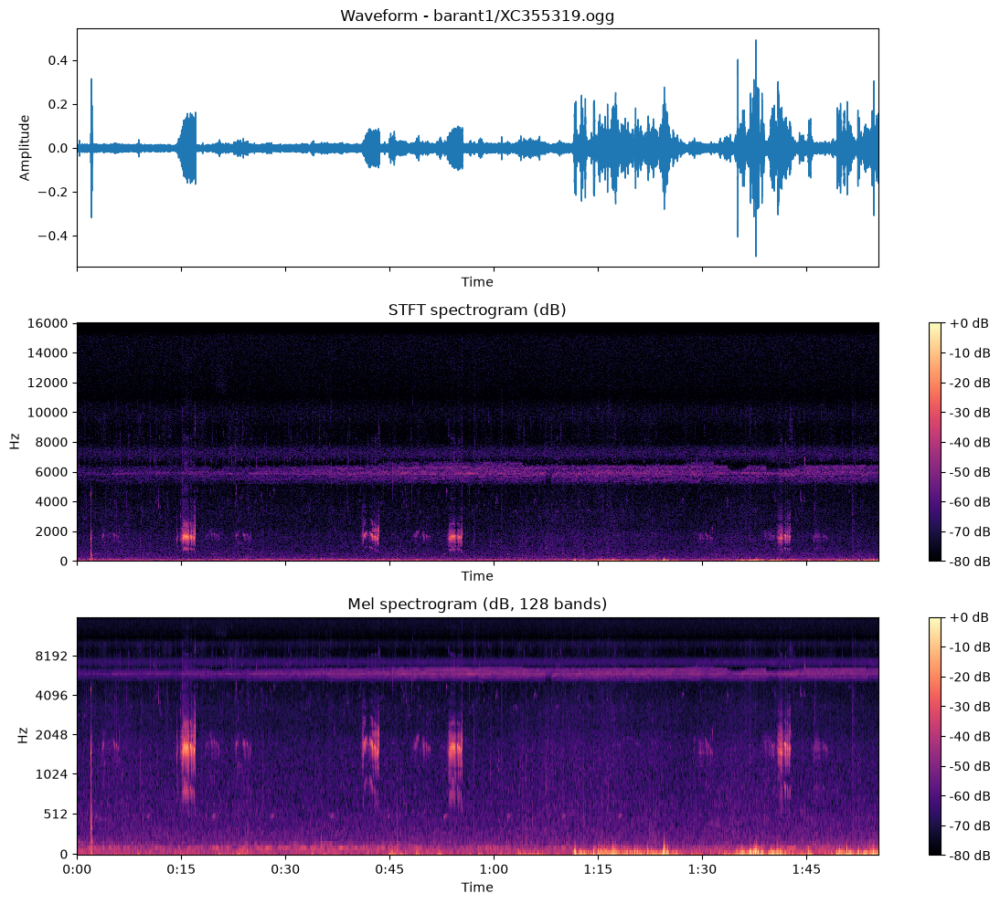

In [ ]:
sample_number = 1956  # Index into train_audio_files; change it to see another clip.

sample_file = train_audio_files[sample_number]
label_row = train_audio_label_df.loc[sample_file]
print(f"File: {sample_file}")
print(f"Species: {label_row['common_name']} ({label_row['scientific_name']}), "
      f"label {label_row['primary_label']}, class {label_row['class_name']}")
display(train_audio_metadata_df.loc[[sample_file]])

y, sr = librosa.load(train_audio_dir / sample_file, sr=None)  # Native sample rate
play(y, sr)
plot_recording(y, sr, sample_file, figsize=(12, 10))
plt.tight_layout()
plt.show()

### Soundscape with its interval labels
Dashed lines mark the labeled 5-second intervals; the species labels are written at the top
of each interval.

File: BC2026_Train_0001_S08_20250606_030007.ogg
Labels per interval:
  00:00:00 - 00:00:05: ['47158son13', '47158son17', '47158son22', '47158son23', '47158son25']
  00:00:05 - 00:00:10: ['47158son13', '47158son17', '47158son21', '47158son22', '47158son23', '47158son25']
  00:00:10 - 00:00:15: ['47158son13', '47158son17', '47158son21', '47158son22', '47158son23', '47158son25']
  00:00:15 - 00:00:20: ['47158son13', '47158son17', '47158son21', '47158son22', '47158son23', '47158son25']
  00:00:20 - 00:00:25: ['47158son10', '47158son13', '47158son17', '47158son21', '47158son22', '47158son23', '47158son25']
  00:00:25 - 00:00:30: ['47158son10', '47158son13', '47158son17', '47158son21', '47158son22', '47158son23', '47158son25']
  00:00:30 - 00:00:35: ['47158son10', '47158son13', '47158son17', '47158son21', '47158son22', '47158son23', '47158son25']
  00:00:35 - 00:00:40: ['47158son10', '47158son13', '47158son17', '47158son21', '47158son22', '47158son23', '47158son25']
  00:00:40 - 00:00:45: ['

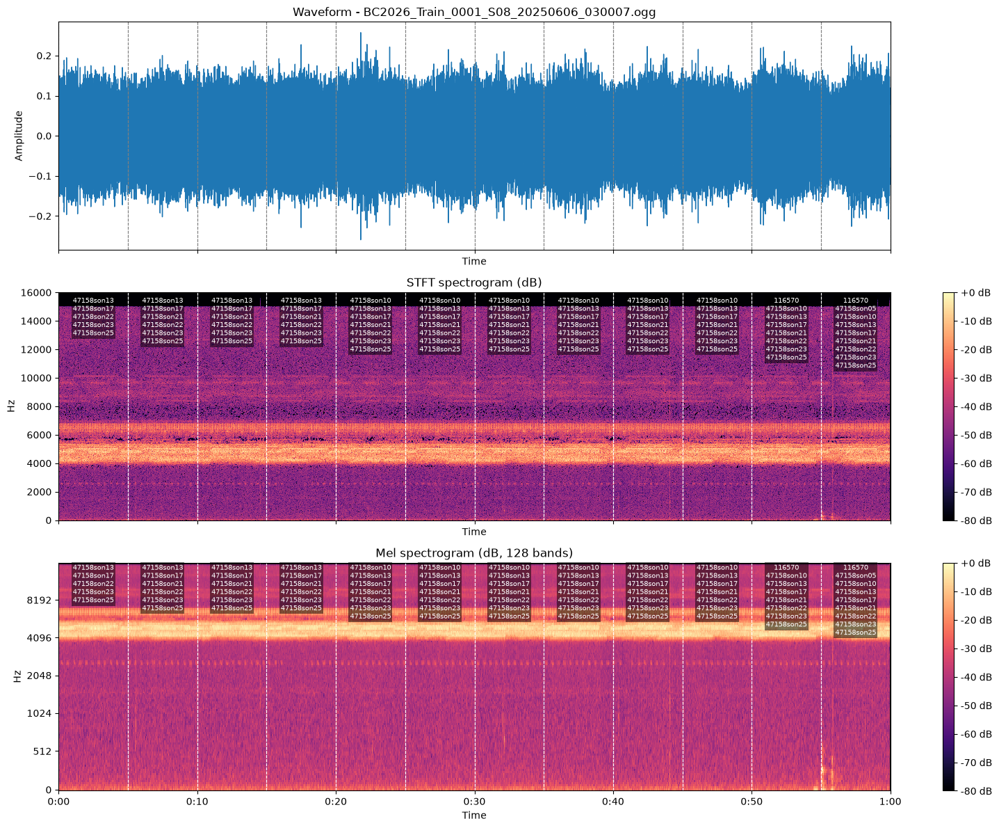

In [ ]:
def time_to_seconds(t):
    """Convert 'HH:MM:SS' to seconds."""
    h, m, s = (int(x) for x in t.split(":"))
    return h * 3600 + m * 60 + s


soundscape_number = 0  # Index into the labeled soundscape files; change it to see another one.

labeled_soundscape_files = sorted(soundscapes_df["filename"].unique())
soundscape_file = labeled_soundscape_files[soundscape_number]
sections = soundscapes_df[soundscapes_df["filename"] == soundscape_file].sort_values("start")

print(f"File: {soundscape_file}")
print("Labels per interval:")
for row in sections.itertuples():
    print(f"  {row.start} - {row.end}: {row.labels}")
print("Species:")
for label in sorted({label for labels in sections["labels"] for label in labels}):
    name = taxonomy_df.loc[label, "common_name"] if label in taxonomy_df.index else "?"
    print(f"  {label}: {name}")

y, sr = librosa.load(train_soundscapes_dir / soundscape_file, sr=None)  # Native sample rate
play(y, sr)
fig, axes = plot_recording(y, sr, soundscape_file, figsize=(16, 12))

# Mark the labeled intervals on every panel and write their species on the spectrograms
for ax in axes:
    for row in sections.itertuples():
        for boundary in (time_to_seconds(row.start), time_to_seconds(row.end)):
            ax.axvline(boundary, color="white" if ax is not axes[0] else "gray", linestyle="--", linewidth=0.8)
for ax in axes[1:]:
    ymax = ax.get_ylim()[1]
    for row in sections.itertuples():
        start, end = time_to_seconds(row.start), time_to_seconds(row.end)
        ax.text(
            (start + end) / 2, ymax * 0.98, "\n".join(row.labels),
            ha="center", va="top", fontsize=7, color="white",
            bbox=dict(facecolor="black", alpha=0.5, pad=1.5, edgecolor="none"),
        )
plt.tight_layout()
plt.show()

# Part 2 - Data preparation for training
Builds the training, validation and test inputs and outputs (ported from `data-exploration (13).ipynb`, Sections 4-9).

- **Outputs (targets):** a 0/1 vector over all taxonomy species per example; primary and secondary labels are kept separately.
- **Inputs:** every recording is cut into 5-second windows and each window is turned into a 1,536-number embedding by the
  pretrained, frozen [Google Perch v2](https://www.kaggle.com/models/google/bird-vocalization-classifier/tensorFlow2/perch_v2/2) model.
  A training clip becomes a *bag* of windows (its labels apply to the whole recording); each labeled soundscape interval is a bag with one window.
- **Split:** by recording, so windows of one file never end up in different splits.
- Everything is written to `data/prepared/` (git-ignored).

**Requirements:** TensorFlow, and a GPU for the full dataset (Colab or Kaggle; the full export takes about an hour on a Kaggle GPU).
The Perch model is downloaded with `kagglehub` using the same Kaggle token as the data download.
For a quick test without a GPU, set `ALLOW_CPU = True` below and `PILOT_FILES_PER_SOURCE` (Section 8) to a small number, e.g. 20.

The adapter cell converts the tables from Part 1 (short clips already removed) into the form the ported code expects.

In [ ]:
import ast
import hashlib
import json
import shutil
from collections import Counter, deque
from concurrent.futures import ThreadPoolExecutor
from time import perf_counter

import soundfile as sf
import tensorflow as tf
from tqdm.auto import tqdm

# ------------------------------------------------------------------ settings
SEED = 42
AUDIO_TRAIN_RATIO, AUDIO_VAL_RATIO, AUDIO_TEST_RATIO = 0.80, 0.10, 0.10
SOUNDSCAPE_TRAIN_RATIO, SOUNDSCAPE_VAL_RATIO, SOUNDSCAPE_TEST_RATIO = 0.70, 0.15, 0.15
SAMPLE_RATE = 32000  # Perch v2 input: 5-second windows at 32 kHz.
WINDOW_SAMPLES = int(SAMPLE_RATE * WINDOW_SECONDS)
BATCH_SIZE = 1  # Bags per batch in the Section 11 loaders.
OUTPUT_DIR = DATA_ROOT / "prepared"  # Inside the git-ignored data/ folder.
PERCH_MODEL_PATH = None  # Folder with saved_model.pb; None = find on Kaggle or download with kagglehub.
ALLOW_CPU = False  # True: run Perch on the CPU (slow; only for small pilot runs).

assert abs(AUDIO_TRAIN_RATIO + AUDIO_VAL_RATIO + AUDIO_TEST_RATIO - 1) < 1e-9
assert abs(SOUNDSCAPE_TRAIN_RATIO + SOUNDSCAPE_VAL_RATIO + SOUNDSCAPE_TEST_RATIO - 1) < 1e-9
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)  # Seeds Python, NumPy and TensorFlow.

# kagglehub (Perch download) uses the same token as the data download; keep its cache in data/.
os.environ.setdefault("KAGGLEHUB_CACHE", str(DATA_ROOT))
if not os.environ.get(KAGGLE_TOKEN):
    load_from_colab_secrets()
if not os.environ.get(KAGGLE_TOKEN):
    load_from_env_file()

print(f"TensorFlow {tf.__version__}; GPUs: {tf.config.list_physical_devices('GPU')}")
print(f"Prepared data will be written to: {OUTPUT_DIR}")


# ------------------------------------------------------------------ label/time parsers used by Sections 7-12
def parse_label_field(value, list_format=False):
    """Parse a label field ("['a', 'b']" list or "a;b" string) without silently dropping bad values."""
    if pd.isna(value) or str(value).strip() == "":
        if list_format:
            return []
        raise ValueError("An annotation label field is empty.")
    text = str(value).strip()
    if list_format or text.startswith("["):
        try:
            labels = ast.literal_eval(text)
        except (ValueError, SyntaxError) as error:
            raise ValueError(f"Invalid label list: {text!r}") from error
        if not isinstance(labels, (list, tuple)):
            raise ValueError(f"Expected a label list: {text!r}")
    else:
        labels = text.split(";")
    labels = [str(label).strip() for label in labels]
    if any(not label for label in labels):
        raise ValueError(f"Empty label inside field: {text!r}")
    return list(dict.fromkeys(labels))


def parse_time_seconds(value):
    """Accept numeric seconds or HH:MM:SS timestamps."""
    try:
        seconds = float(value)
    except (TypeError, ValueError):
        seconds = pd.to_timedelta(str(value)).total_seconds()
    if not np.isfinite(seconds):
        raise ValueError(f"Nonfinite annotation time: {value!r}")
    return seconds


# ------------------------------------------------------------------ adapter: Part 1 tables -> Part 2 names
# Taxonomy in its original row order (this order defines the class indices).
taxonomy_clean_df = taxonomy_df.reset_index()
known_labels = set(taxonomy_clean_df["primary_label"])

# Training clips: filename back as a column; short clips were already removed in Section 1.
train_clean_df = train_audio_label_df.reset_index()
missing_columns = {"filename", "primary_label", "secondary_labels", "rating"} - set(train_clean_df.columns)
if missing_columns:
    raise ValueError(f"train.csv is missing columns: {sorted(missing_columns)}")
train_clean_df["secondary_labels"] = [
    repr(sorted(parse_label_field(value, list_format=True))) for value in train_clean_df["secondary_labels"]
]

# Soundscapes: one row per labeled (file, start, end) interval with its species joined by ";".
soundscape_clean_df = (
    soundscapes_df[["filename", "start", "end", "labels"]]
    .explode("labels")
    .dropna(subset=["labels"])
    .groupby(["filename", "start", "end"], as_index=False, sort=True)["labels"]
    .agg(lambda labels: ";".join(sorted(set(labels))))
    .rename(columns={"labels": "primary_label"})
)
dropped_intervals = len(soundscapes_df.drop_duplicates(["filename", "start", "end"])) - len(soundscape_clean_df)

# Checks: every label is in the taxonomy and every soundscape interval is exactly 5 seconds.
used_labels = set(train_clean_df["primary_label"])
used_labels.update(label for value in train_clean_df["secondary_labels"] for label in ast.literal_eval(value))
used_labels.update(label for value in soundscape_clean_df["primary_label"] for label in value.split(";"))
unknown_labels = used_labels - known_labels
if unknown_labels:
    raise ValueError(f"Labels missing from the taxonomy: {sorted(unknown_labels)}")
interval_lengths = (soundscape_clean_df["end"].map(parse_time_seconds)
                    - soundscape_clean_df["start"].map(parse_time_seconds))
if not np.allclose(interval_lengths, WINDOW_SECONDS):
    raise ValueError("Every soundscape interval must be exactly 5 seconds long.")

print(f"Taxonomy classes: {len(taxonomy_clean_df)}")
print(f"Training clips: {len(train_clean_df):,}")
print(f"Labeled soundscape intervals: {len(soundscape_clean_df):,} "
      f"from {soundscape_clean_df['filename'].nunique()} files"
      + (f" ({dropped_intervals} intervals without labels skipped)" if dropped_intervals else ""))

## 7. Class mapping and label targets
Encodes primary and secondary labels as separate 0/1 vectors in taxonomy order, verifies them, and saves them to `labels/`.

In [ ]:
# ============================================================
# 7.1 - CLASS MAPPING AND TARGET ENCODING
# ============================================================

class_names = taxonomy_clean_df["primary_label"].tolist()
N_CLASSES = len(class_names)

class_to_idx = {
    label: index for index, label in enumerate(class_names)
}
idx_to_class = {
    index: label for index, label in enumerate(class_names)
}


def encode_labels(labels, class_to_idx, n_classes):
    """Encode labels using the shared taxonomy order."""
    vector = np.zeros(n_classes, dtype=np.uint8)

    for label in labels:
        if label not in class_to_idx:
            raise ValueError(f"Unknown class label: {label}")
        vector[class_to_idx[label]] = 1

    return vector


# Individual recordings: preserve primary and secondary roles.
train_clean_df["primary_list"] = (
    train_clean_df["primary_label"].map(lambda label: [label])
)
train_clean_df["secondary_list"] = (
    train_clean_df["secondary_labels"].map(
        lambda value: parse_label_field(value, list_format=True)
    )
)

# Soundscapes: all interval labels enter the primary vector.
soundscape_clean_df["primary_list"] = (
    soundscape_clean_df["primary_label"].map(parse_label_field)
)
soundscape_clean_df["secondary_list"] = [
    [] for _ in range(len(soundscape_clean_df))
]

# Keep label unions for the subsequent class-aware splitting.
# No combined target vector is stored.
for frame in [train_clean_df, soundscape_clean_df]:
    frame["all_labels"] = [
        list(dict.fromkeys(primary + secondary))
        for primary, secondary in zip(
            frame["primary_list"], frame["secondary_list"]
        )
    ]

audio_primary_targets = np.stack([
    encode_labels(labels, class_to_idx, N_CLASSES)
    for labels in train_clean_df["primary_list"]
])
audio_secondary_targets = np.stack([
    encode_labels(labels, class_to_idx, N_CLASSES)
    for labels in train_clean_df["secondary_list"]
])

soundscape_primary_targets = np.stack([
    encode_labels(labels, class_to_idx, N_CLASSES)
    for labels in soundscape_clean_df["primary_list"]
])
soundscape_secondary_targets = np.stack([
    encode_labels(labels, class_to_idx, N_CLASSES)
    for labels in soundscape_clean_df["secondary_list"]
])

print("OK: shared class mapping and separate target vectors created.")


# ============================================================
# 7.2 - VALIDATE TARGETS AND RECORD IDENTIFIERS
# ============================================================

def validate_targets(frame, primary, secondary, source):
    """Verify dimensions, values and exact label reconstruction."""
    expected_shape = (len(frame), N_CLASSES)

    for name, targets in [
        ("primary", primary),
        ("secondary", secondary),
    ]:
        if targets.shape != expected_shape:
            raise ValueError(
                f"{source}: invalid {name} target shape: {targets.shape}"
            )

        if targets.dtype != np.uint8 or not np.isin(targets, [0, 1]).all():
            raise ValueError(
                f"{source}: {name} targets must be binary uint8 arrays."
            )

        for position, (labels, vector) in enumerate(
            zip(frame[f"{name}_list"], targets)
        ):
            recovered = {
                idx_to_class[index] for index in np.flatnonzero(vector)
            }

            if recovered != set(labels):
                raise ValueError(
                    f"{source}: {name} label mismatch at position {position}."
                )

    if source == "audio":
        if not np.all(primary.sum(axis=1) == 1):
            raise ValueError(
                "audio: each recording must have exactly one primary label."
            )
    else:
        if not np.all(primary.sum(axis=1) >= 1):
            raise ValueError(
                "soundscape: each interval must have annotated labels."
            )

        if secondary.any():
            raise ValueError(
                "soundscape: secondary targets must contain only zeros."
            )


if "rating" not in train_clean_df.columns:
    raise ValueError("train.csv must contain the rating column to preserve ratings.")
audio_metadata = train_clean_df[["filename"]].copy()
audio_metadata["rating"] = pd.to_numeric(
    train_clean_df["rating"], errors="raise"
).to_numpy(dtype=np.float64)
audio_metadata["source"] = "audio"
audio_metadata["sample_id"] = (
    "audio:" + audio_metadata["filename"]
)

soundscape_metadata = soundscape_clean_df[
    ["filename", "start", "end"]
].copy()
soundscape_metadata["source"] = "soundscape"
soundscape_metadata["rating"] = np.nan  # No recording rating is supplied.

for column in ["start", "end"]:
    soundscape_metadata[column] = (
        soundscape_metadata[column].map(parse_time_seconds)
    )

soundscape_metadata["sample_id"] = [
    "soundscape:" + json.dumps(
        [filename, start, end], ensure_ascii=False
    )
    for filename, start, end in zip(
        soundscape_metadata["filename"],
        soundscape_metadata["start"],
        soundscape_metadata["end"],
    )
]

target_sets = {
    "audio": (
        train_clean_df,
        audio_metadata,
        audio_primary_targets,
        audio_secondary_targets,
    ),
    "soundscape": (
        soundscape_clean_df,
        soundscape_metadata,
        soundscape_primary_targets,
        soundscape_secondary_targets,
    ),
}

for source, (frame, metadata, primary, secondary) in target_sets.items():
    validate_targets(frame, primary, secondary, source)

    if len(metadata) != len(frame) or not metadata["sample_id"].is_unique:
        raise ValueError(
            f"{source}: missing or duplicated sample identifiers."
        )

print("OK: target vectors and sample identifiers verified.")


# ============================================================
# 7.3 - EXPORT AND VERIFY SAVED LABEL DATA
# ============================================================

LABEL_DIR = OUTPUT_DIR / "labels"
LABEL_DIR.mkdir(parents=True, exist_ok=True)

class_mapping_df = pd.DataFrame({
    "class_index": np.arange(N_CLASSES),
    "class_label": class_names,
})

mapping_path = LABEL_DIR / "class_mapping.csv"
class_mapping_df.to_csv(mapping_path, index=False)

loaded_mapping = pd.read_csv(
    mapping_path,
    dtype={"class_label": str},
)

if (
    loaded_mapping["class_label"].tolist() != class_names
    or loaded_mapping["class_index"].tolist() != list(range(N_CLASSES))
):
    raise ValueError("Saved class mapping differs from the original.")

for source, (_, metadata, primary, secondary) in target_sets.items():
    metadata_path = LABEL_DIR / f"{source}_metadata.csv"
    targets_path = LABEL_DIR / f"{source}_targets.npz"

    metadata.to_csv(metadata_path, index=False)

    sample_ids = metadata["sample_id"].to_numpy(dtype=str)

    np.savez_compressed(
        targets_path,
        sample_ids=sample_ids,
        primary_target=primary,
        secondary_target=secondary,
    )

    loaded_metadata = pd.read_csv(
        metadata_path,
        dtype={
            "sample_id": str,
            "filename": str,
            "source": str,
        },
    )

    pd.testing.assert_frame_equal(
        metadata.reset_index(drop=True),
        loaded_metadata,
        check_dtype=False,
        check_exact=True,
        obj=f"{source} metadata",
    )

    with np.load(targets_path, allow_pickle=False) as saved:
        for name, expected in [
            ("sample_ids", sample_ids),
            ("primary_target", primary),
            ("secondary_target", secondary),
        ]:
            actual = saved[name]

            if actual.dtype != expected.dtype:
                raise ValueError(
                    f"{source}: saved {name} has an unexpected dtype."
                )

            np.testing.assert_array_equal(
                actual,
                expected,
                err_msg=f"{source}: saved {name} differs from the original.",
            )

print(f"OK: label data exported and verified in {LABEL_DIR}.")

## 8. Frozen Perch v2 encoder and file selection
Loads the pretrained Perch v2 SavedModel (frozen; it is never trained here) and checks its
input/output signature with a probe batch. Also defines the shared waveform preprocessing:
non-overlapping 5-second windows, zero-padding of the last window, and per-window abs-max
normalization.

The second cell chooses which recordings to export. Set `PILOT_FILES_PER_SOURCE` (e.g. 200)
for a quick pilot; `None` exports everything.

In [ ]:
# Perch v2 expects 5-second windows at 32 kHz. A GPU is required unless ALLOW_CPU is True.
NORMALIZATION_EPSILON = 1e-6  # Floor for the per-window abs-max normalization.
if SAMPLE_RATE != 32000 or WINDOW_SAMPLES != 160000:
    raise ValueError("This configuration expects 5-second windows at 32 kHz.")
GPUS = tf.config.list_physical_devices("GPU")
if not GPUS and not ALLOW_CPU:
    raise RuntimeError("No GPU available. Run on Colab/Kaggle with a GPU, "
                       "or set ALLOW_CPU = True (Part 2 settings) for a small pilot run.")


# ============================================================
# 8.1 - SHARED WAVEFORM PREPROCESSING
# ============================================================

def make_windows(waveform):
    """Preserve the waveform; right-pad only the last 5-second window."""
    waveform = np.asarray(waveform, dtype=np.float32)
    if waveform.ndim != 1 or not len(waveform) or not np.isfinite(waveform).all():
        raise ValueError("Expected a finite, nonempty mono waveform.")
    count = (len(waveform) + WINDOW_SAMPLES - 1) // WINDOW_SAMPLES
    valid = np.minimum(
        WINDOW_SAMPLES, len(waveform) - np.arange(count) * WINDOW_SAMPLES
    ).astype(np.int32)
    windows = np.pad(
        waveform, (0, count * WINDOW_SAMPLES - len(waveform))
    ).reshape(count, WINDOW_SAMPLES)
    return windows, valid


def extract_interval(waveform, start, end, sample_rate):
    """Slice in native sample coordinates, before resampling."""
    if not np.isfinite([start, end]).all():
        raise ValueError("Annotation boundaries must be finite.")
    if start < 0 or not np.isclose(
        end - start, WINDOW_SECONDS, atol=1e-6, rtol=0
    ):
        raise ValueError("Expected a nonnegative, 5-second interval.")
    left, right = int(round(start * sample_rate)), int(round(end * sample_rate))
    # Allow one sample of boundary discrepancy, as in the previous loader.
    if left >= len(waveform) or right > len(waveform) + 1:
        raise ValueError("Annotated interval exceeds the decoded audio.")
    return waveform[left:min(right, len(waveform))]


# ============================================================
# 8.2 - LOAD AND CHECK THE FROZEN PERCH V2 MODEL
# ============================================================

# Frozen Perch v2: own waveform frontend; do not feed standardized mel images.
PERCH_HANDLE = "google/bird-vocalization-classifier/tensorFlow2/perch_v2/2"
EMBEDDING_DIM = 1536
GPU_WINDOW_BATCH = 32  # Lower to 4 or 8 if embedding extraction runs out of GPU RAM.

if PERCH_MODEL_PATH is None:
    matches = sorted(Path("/kaggle/input").glob(
        "**/perch_v2/2/saved_model.pb"))
    if len(matches) > 1:
        raise ValueError("Multiple Perch models found; set PERCH_MODEL_PATH explicitly.")
    if matches:
        PERCH_MODEL_PATH = str(matches[0].parent)
    else:
        try:
            import kagglehub
            if os.environ.get("KAGGLE_API_TOKEN"):
                from kagglehub.config import set_kaggle_api_token
                set_kaggle_api_token(os.environ["KAGGLE_API_TOKEN"])
            PERCH_MODEL_PATH = kagglehub.model_download(PERCH_HANDLE)
        except Exception as error:
            raise RuntimeError(
                "Attach Google Perch TensorFlow2 perch_v2 version 2 and set "
                "PERCH_MODEL_PATH to its SavedModel folder, or enable Internet "
                "for kagglehub download. No fallback to random weights is used."
            ) from error
if not (Path(PERCH_MODEL_PATH) / "saved_model.pb").is_file():
    raise FileNotFoundError(f"No saved_model.pb in {PERCH_MODEL_PATH}")

try:
    perch = tf.saved_model.load(str(PERCH_MODEL_PATH))
except Exception as error:
    raise RuntimeError("Perch SavedModel could not load. Check the model version "
                       "and TensorFlow compatibility; inspect the original error.") from error

# Inspect the public SavedModel signature rather than assume an input key.
if "serving_default" not in perch.signatures:
    raise ValueError(f"Missing serving_default; available: {list(perch.signatures)}")
perch_function = perch.signatures["serving_default"]
positional, keyword = perch_function.structured_input_signature
if len(keyword) == 1:
    input_key, input_spec = next(iter(keyword.items()))
elif len(positional) == 1 and not keyword:
    input_key, input_spec = None, positional[0]
else:
    raise ValueError(f"Unexpected Perch input signature: {perch_function.structured_input_signature}")
if input_spec.shape.rank != 2 or input_spec.shape[-1] != WINDOW_SAMPLES:
    raise ValueError(f"Expected [batch,160000] waveform input, found {input_spec}")
if input_spec.dtype != tf.float32:
    raise ValueError(f"Unexpected Perch input dtype: {input_spec.dtype}")
if input_spec.shape[0] is not None:
    # Keep original windows, padding only inference microbatches if needed.
    GPU_WINDOW_BATCH = int(input_spec.shape[0])

def call_perch(waveforms):
    if input_key is None:
        return perch_function(waveforms)
    return perch_function(**{input_key: waveforms})

probe_outputs = call_perch(tf.zeros([GPU_WINDOW_BATCH, WINDOW_SAMPLES], tf.float32))
embedding_keys = [key for key, value in probe_outputs.items()
                  if "embedding" in key.lower() and value.shape.rank == 2
                  and value.shape[-1] == EMBEDDING_DIM]
if len(embedding_keys) != 1:
    raise ValueError(f"Expected one pooled embedding output; found "
                     f"{ {k: str(v.shape) for k,v in probe_outputs.items()} }")
PERCH_EMBEDDING_KEY = embedding_keys[0]
tf.debugging.assert_all_finite(probe_outputs[PERCH_EMBEDDING_KEY], "Invalid Perch probe")
probe_outputs[PERCH_EMBEDDING_KEY].numpy()  # Synchronize preflight.
print(f"OK: Perch v2 loaded; output={PERCH_EMBEDDING_KEY}, width={EMBEDDING_DIM}.")
del probe_outputs

def windows_to_embeddings(windows):
    # Per-window abs-max amplitude normalization, including silence protection.
    waveforms = tf.convert_to_tensor(windows, dtype=tf.float32)
    scale = tf.reduce_max(tf.abs(waveforms), axis=1, keepdims=True)
    waveforms = waveforms / tf.maximum(scale, tf.constant(NORMALIZATION_EPSILON, tf.float32))
    count = int(waveforms.shape[0])
    fixed = input_spec.shape[0]
    if fixed is not None and count < int(fixed):
        waveforms = tf.pad(waveforms, [[0, int(fixed)-count], [0, 0]])
    with tf.device("/GPU:0" if GPUS else "/CPU:0"):
        outputs = call_perch(waveforms)
    embeddings = outputs[PERCH_EMBEDDING_KEY][:count].numpy().astype(np.float32)
    if embeddings.shape != (count, EMBEDDING_DIM):
        raise ValueError(f"Unexpected embedding shape: {embeddings.shape}")
    return embeddings

In [ ]:
# ============================================================
# 8.3 - SELECT RECORDINGS TO EXPORT
# ============================================================

# Set to None for the complete dataset. This limits FILES, not intervals.
PILOT_FILES_PER_SOURCE = None


def select_source_files(frame, limit, seed):
    """Select unique recordings, preserving all their annotated examples."""
    names = sorted(frame["filename"].unique())
    if limit is not None:
        if not isinstance(limit, int) or limit < 1:
            raise ValueError("File limit must be a positive integer or None.")
        if len(names) > limit:
            rng = np.random.default_rng(seed)
            names = sorted(rng.choice(names, size=limit, replace=False).tolist())
    return frame.loc[frame["filename"].isin(names)].copy()


sources = {
    "audio": (audio_metadata, DATA_DIR / "train_audio",
              audio_primary_targets, audio_secondary_targets),
    "soundscape": (soundscape_metadata, DATA_DIR / "train_soundscapes",
                   soundscape_primary_targets, soundscape_secondary_targets),
}
selected_sources = {}
for source, (metadata, directory, primary, secondary) in sources.items():
    if primary.shape != (len(metadata), N_CLASSES) or secondary.shape != primary.shape:
        raise ValueError(f"{source}: target arrays do not match metadata.")
    frame = metadata.reset_index(drop=True).copy()
    frame["target_position"] = np.arange(len(frame))
    selected_sources[source] = select_source_files(frame, PILOT_FILES_PER_SOURCE, SEED)

selected_ids = pd.concat(list(selected_sources.values()))["sample_id"]
if selected_ids.empty or selected_ids.isna().any() or not selected_ids.is_unique:
    raise ValueError("Selected sample identifiers are empty, missing or duplicated.")

selection_text = "; ".join(
    f"{source}: {frame['filename'].nunique():,} files, {len(frame):,} bags"
    for source, frame in selected_sources.items()
)
print(f"OK: examples selected ({selection_text}).")

## 9. Export embeddings (resumable)
Decodes each selected recording once, runs Perch (on the GPU if available) in batches of windows, and writes
one compressed NPZ per bag into `FEATURE_DIR`. Every finished bag is appended to
`completed.jsonl`; if the export is interrupted, rerun the three Section 9 cells and it
continues where it stopped. A fingerprint of the data and settings prevents resuming into a
folder that was created with different settings.

In [ ]:
# ============================================================
# 9.1 - OUTPUT FOLDER, CONFIG AND RESUME STATE
# ============================================================

# Batched export: fixed directory + append-only completion journal allow resuming.
DECODE_WORKERS = 2
PREFETCH_FILES = 2  # Bound decoded recordings in RAM.
mode = "full" if PILOT_FILES_PER_SOURCE is None else "pilot"
FEATURE_DIR = OUTPUT_DIR / f"perch_embeddings_batched_{mode}"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)
config = {
    "representation": "perch_v2_frozen_embeddings",
    "model_handle": PERCH_HANDLE,
    "model_path": str(PERCH_MODEL_PATH),
    "embedding_output": PERCH_EMBEDDING_KEY,
    "embedding_dimension": EMBEDDING_DIM,
    "sample_rate": SAMPLE_RATE,
    "window_seconds": WINDOW_SECONDS,
    "window_samples": WINDOW_SAMPLES,
    "shape_per_window": [EMBEDDING_DIM],
    "normalization": "waveform_per_window_abs_max_floor_1e-6",
    "feature_dtype": "float32",
    "seed": SEED,
    "pilot_files_per_source": PILOT_FILES_PER_SOURCE,
    "tensorflow_version": tf.__version__,
    "gpu_window_batch": GPU_WINDOW_BATCH,
    "verify_saved_content": False,
}
# Resume requires the same model, selection, targets and preprocessing contract.
digest = hashlib.sha256()
for source, frame in selected_sources.items():
    digest.update(source.encode())
    digest.update(frame.to_json(orient="split", double_precision=15).encode())
    digest.update(np.asarray(sources[source][2]).tobytes())
    digest.update(np.asarray(sources[source][3]).tobytes())
contract = {
    key: value for key, value in config.items()
    if key not in {"model_path", "gpu_window_batch"}
}
digest.update(json.dumps(contract, sort_keys=True).encode())
fingerprint = digest.hexdigest()
state_path = FEATURE_DIR / "export_state.json"
if state_path.exists():
    if json.loads(state_path.read_text())["fingerprint"] != fingerprint:
        raise ValueError("Existing export uses different data/settings. Choose a new FEATURE_DIR.")
else:
    state_path.write_text(json.dumps({"fingerprint": fingerprint}), encoding="utf-8")
(FEATURE_DIR / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
(FEATURE_DIR / "class_names.json").write_text(json.dumps(class_names), encoding="utf-8")

journal = FEATURE_DIR / "completed.jsonl"
completed = {}
if journal.exists():
    # Discard an incomplete final line left by an interrupted append.
    raw = journal.read_bytes()
    if raw and not raw.endswith(b"\n"):
        raw = raw[:raw.rfind(b"\n")+1]
        journal.write_bytes(raw)
    for line in raw.splitlines():
        row = json.loads(line)
        path = FEATURE_DIR / row["feature_file"]
        if not path.is_file() or path.stat().st_size != row["saved_bytes"]:
            raise ValueError(f"Missing/truncated completed export: {path}")
        completed[row["sample_id"]] = row
if set(completed) - set(selected_ids):
    raise ValueError("Resume journal contains unexpected examples.")

jobs = []
for source, frame in selected_sources.items():
    for filename, examples in frame.groupby("filename", sort=True):
        remaining = examples[~examples["sample_id"].isin(completed)]
        if not remaining.empty:
            jobs.append((source, filename, remaining))

In [ ]:
# ============================================================
# 9.2 - DECODING, EMBEDDING AND SAVING HELPERS
# ============================================================

def decode_job(job):
    source, filename, examples = job
    start_time = perf_counter()
    path = str(sources[source][1] / filename)
    info = sf.info(path)
    native, sr = sf.read(path, dtype="float32", always_2d=True)
    if sr <= 0 or not len(native) or not np.isfinite(native).all():
        raise ValueError(f"Invalid decoded audio: {filename}")
    mono = native.mean(axis=1) if native.shape[1] > 1 else native[:, 0]
    bags = []
    for row in examples.itertuples(index=False):
        segment = mono if source == "audio" else extract_interval(mono, float(row.start), float(row.end), sr)
        if sr != SAMPLE_RATE:
            segment = librosa.resample(segment, orig_sr=sr, target_sr=SAMPLE_RATE)
        if source == "soundscape":
            if abs(len(segment)-WINDOW_SAMPLES) > 1:
                raise ValueError(f"Invalid interval: {row.sample_id}")
            segment = segment[:WINDOW_SAMPLES]
        windows, valid = make_windows(segment)
        bags.append((row, windows, valid))
    stats = {
        "seconds": perf_counter() - start_time,
        "resampled": int(sr != SAMPLE_RATE),
        "mono": int(native.shape[1] != 1),
        "files": 1,
        "header_sample_difference": int(info.frames - len(native)),
    }
    return source, filename, bags, stats

def bounded_decodes(jobs):
    # Do not submit the entire dataset: completed futures hold decoded audio.
    with ThreadPoolExecutor(max_workers=DECODE_WORKERS) as pool:
        pending = deque()
        iterator = iter(jobs)
        for _ in range(PREFETCH_FILES):
            job = next(iterator, None)
            if job is not None:
                pending.append(pool.submit(decode_job, job))
        while pending:
            result = pending.popleft().result()
            job = next(iterator, None)
            if job is not None:
                pending.append(pool.submit(decode_job, job))
            yield result


def save_bag(key):
    item = active.pop(key)
    row, source, filename = item["row"], item["source"], item["filename"]
    primary = sources[source][2][int(row.target_position)]
    secondary = sources[source][3][int(row.target_position)]
    for target in [primary, secondary]:
        if target.shape != (N_CLASSES,) or not np.isin(target, [0,1]).all():
            raise ValueError(f"Invalid labels: {key}")
    if source == "soundscape" and (secondary.any() or len(item["features"]) != 1):
        raise ValueError(f"Invalid soundscape bag: {key}")
    record = f"{source}:{filename}"
    target = FEATURE_DIR / f"bag_{hashlib.sha256(key.encode()).hexdigest()}.npz"
    temporary = target.with_suffix(".partial")
    start_time = perf_counter()
    with temporary.open("wb") as stream:
        np.savez_compressed(
            stream,
            features=item["features"],
            valid_samples=item["valid"],
            primary_target=primary,
            secondary_target=secondary,
            sample_id=np.asarray(key),
            recording_id=np.asarray(record),
            source=np.asarray(source),
            rating=np.asarray(row.rating, dtype=np.float64),
        )
    os.replace(temporary, target)
    metadata = {
        "sample_id": key,
        "recording_id": record,
        "source": source,
        "filename": filename,
        "rating": float(row.rating),
        "start": float(row.start) if source == "soundscape" else np.nan,
        "end": float(row.end) if source == "soundscape" else np.nan,
        "feature_file": target.name,
        "n_windows": len(item["features"]),
        "n_valid_samples": int(item["valid"].sum()),
        "saved_bytes": target.stat().st_size,
    }
    with journal.open("a", encoding="utf-8") as stream:
        stream.write(json.dumps(metadata)+"\n")
        stream.flush()
    completed[key] = metadata
    timings["save_seconds"] += perf_counter()-start_time

def flush_batch():
    global processed_windows
    if not batch_windows:
        return
    start_time = perf_counter()
    embeddings = windows_to_embeddings(np.stack(batch_windows))
    timings["perch_seconds"] += perf_counter()-start_time
    if not np.isfinite(embeddings).all():
        raise ValueError("Nonfinite Perch embeddings.")
    ready = []
    for vector, (key, index) in zip(embeddings, owners):
        active[key]["features"][index] = vector
        active[key]["remaining"] -= 1
        if active[key]["remaining"] == 0:
            ready.append(key)
    for key in ready:
        save_bag(key)
    processed_windows += len(batch_windows)
    progress.update(len(batch_windows))
    batch_windows.clear()
    owners.clear()

In [ ]:
# ============================================================
# 9.3 - RUN THE EXPORT
# ============================================================

timings = {"decode_worker_seconds": 0.0, "perch_seconds": 0.0,
           "save_seconds": 0.0, "main_wait_seconds": 0.0}
counts = {"files": 0, "resampled": 0, "mono": 0}
length_differences = []
active = {}
batch_windows, owners = [], []
started = perf_counter()
processed_windows = 0
estimated_total = sum(int(r["n_windows"]) for r in completed.values())
# Header-based estimate of the number of windows still to embed.
for source, filename, examples in jobs:
    info = sf.info(str(sources[source][1] / filename))
    if source == "audio":
        resampled_length = int(np.ceil(info.frames * SAMPLE_RATE / info.samplerate))
        estimated_total += (resampled_length + WINDOW_SAMPLES - 1) // WINDOW_SAMPLES
    else:
        estimated_total += len(examples)
already_windows = sum(int(r["n_windows"]) for r in completed.values())
progress = tqdm(total=estimated_total, initial=already_windows,
                desc="Perch embedding export", unit="window", mininterval=1)

decoded = iter(bounded_decodes(jobs))
try:
    while True:
        wait_start = perf_counter()
        result = next(decoded, None)
        timings["main_wait_seconds"] += perf_counter()-wait_start
        if result is None:
            break
        source, filename, bags, stats = result
        timings["decode_worker_seconds"] += stats["seconds"]
        for name in counts:
            counts[name] += stats[name]
        if stats["header_sample_difference"]:
            length_differences.append({
                "source": source,
                "filename": filename,
                "difference_samples": stats["header_sample_difference"],
            })
        progress.set_postfix(source=source, saved_bags=len(completed), refresh=False)
        for row, windows, valid in bags:
            key = row.sample_id
            active[key] = {
                "row": row,
                "source": source,
                "filename": filename,
                "features": np.empty((len(windows), EMBEDDING_DIM), np.float32),
                "valid": valid,
                "remaining": len(windows),
            }
            for index, window in enumerate(windows):
                batch_windows.append(window)
                owners.append((key, index))
                if len(batch_windows) == GPU_WINDOW_BATCH:
                    flush_batch()
        del bags, result
    flush_batch()
finally:
    decoded.close()
    progress.close()
if active or set(completed) != set(selected_ids):
    raise RuntimeError("Export incomplete. Rerun the three Section 9 cells to resume from the completed bags.")
feature_manifest = pd.DataFrame([completed[key] for key in selected_ids])
feature_manifest.to_csv(FEATURE_DIR / "manifest.csv", index=False)
timings["elapsed_seconds"] = perf_counter()-started
timings["new_windows"] = processed_windows
timings["resumed_bags"] = len(selected_ids)-sum(len(job[2]) for job in jobs)
timings["note"] = "Decode worker time overlaps GPU/write time; do not sum these columns. ETA is header-based and approximate."
(FEATURE_DIR / "timing_summary.json").write_text(json.dumps(timings, indent=2), encoding="utf-8")
pd.DataFrame(length_differences).to_csv(FEATURE_DIR / "audio_length_differences.csv", index=False)
display(feature_manifest.groupby("source").agg(
    recordings=("recording_id","nunique"), bags=("sample_id","size"),
    windows=("n_windows","sum"), saved_bytes=("saved_bytes","sum")))
display(pd.DataFrame([timings]))
print(f"OK: {len(completed):,} bags exported. This run decoded {counts['files']} files; "
      f"resampled {counts['resampled']}, converted to mono {counts['mono']}.")
print("Dataset directory:", FEATURE_DIR)
print(f"Free disk space: {shutil.disk_usage(FEATURE_DIR).free/1024**3:.2f} GiB")

## 10. Recording-level train/validation/test split
Split the exported bags without moving or duplicating NPZ files. Audio ratios
are approximately 80/10/10 with primary-class stratification. Classes with only
one or two audio recordings stay in training. Soundscape ratios are 70/15/15
by source recording; all annotated intervals from one recording remain together.
A greedy selection ensures that classes absent from audio training are supplied
by soundscape training. Validation/test may lack rare classes; coverage is reported.
This grouping does not detect copies under different filenames or shared site/day.
Ratings are preserved as metadata and are not used to select the split.

In [ ]:
"""Recording-level train/validation/test splits for the exported embedding bags."""

SPLIT_NAMES = ["train", "val", "test"]


def _validate_ratios(ratios):
    values = np.asarray(ratios, dtype=float)
    if values.shape != (3,) or not np.isfinite(values).all() or (values <= 0).any() or not np.isclose(values.sum(), 1):
        raise ValueError("Split ratios must contain three positive values summing to one.")


def split_prepared_dataset(frame, classes, seed, audio_ratios, soundscape_ratios,
                           require_full_coverage=True):
    """Assign recordings, never individual windows, to a split.

    Audio is stratified by its primary species. Classes with fewer than three
    recordings remain in training. A greedy soundscape selection supplies any
    classes still missing from training; validation/test are not used for fitting.
    Ratios for soundscapes refer to recordings, not annotated intervals.
    """
    _validate_ratios(audio_ratios)
    _validate_ratios(soundscape_ratios)
    required_columns = {"sample_id", "recording_id", "source", "primary_labels", "secondary_labels"}
    if required_columns - set(frame.columns):
        raise ValueError(f"Missing split fields: {sorted(required_columns - set(frame.columns))}")
    result = frame.sort_values("sample_id").reset_index(drop=True).copy()
    if result.empty or result["sample_id"].isna().any() or not result["sample_id"].is_unique:
        raise ValueError("Example identifiers must be nonempty and unique.")
    if not result["source"].isin(["audio", "soundscape"]).all():
        raise ValueError("Unexpected dataset source.")
    if result["recording_id"].isna().any():
        raise ValueError("Recording identifiers must be present.")
    if result.groupby("recording_id")["source"].nunique().gt(1).any():
        raise ValueError("A recording identifier is shared by different sources.")
    result["all_labels"] = [
        sorted(set(primary) | set(secondary))
        for primary, secondary in zip(result["primary_labels"], result["secondary_labels"])
    ]
    represented = {v for labels in result["all_labels"] for v in labels}
    unknown = represented - set(classes)
    if unknown:
        raise ValueError(f"Unknown classes: {sorted(unknown)}")
    unavailable = set(classes) - represented
    if unavailable and require_full_coverage:
        raise ValueError(f"Classes absent from the exported dataset: {sorted(unavailable)}")
    # A pilot can cover only classes actually present in the selection.
    desired_coverage = set(classes) if require_full_coverage else represented
    result["split"] = ""
    rng = np.random.default_rng(seed)

    audio = result[result["source"] == "audio"].copy()
    if audio["recording_id"].duplicated().any():
        raise ValueError("Audio must have one full-recording bag per recording.")
    if not audio["primary_labels"].map(len).eq(1).all():
        raise ValueError("Every audio bag must have one primary species.")
    audio["primary_class"] = audio["primary_labels"].map(lambda labels: labels[0])
    for _, group in audio.groupby("primary_class", sort=True):
        indices = group.index.to_numpy()[rng.permutation(len(group))]
        count = len(indices)
        n_val = n_test = 0
        if count >= 3:
            n_val = max(1, round(count * audio_ratios[1]))
            n_test = max(1, round(count * audio_ratios[2]))
            while n_val + n_test > count - 1:
                if n_val >= n_test and n_val > 1:
                    n_val -= 1
                else:
                    n_test -= 1
        n_train = count - n_val - n_test
        result.loc[indices[:n_train], "split"] = "train"
        result.loc[indices[n_train:n_train + n_val], "split"] = "val"
        result.loc[indices[n_train + n_val:], "split"] = "test"

    covered = {v for labels in result.loc[result["split"] == "train", "all_labels"] for v in labels}
    needed = desired_coverage - covered
    soundscapes = result[result["source"] == "soundscape"]
    recording_labels = {
        recording: {v for labels in group["all_labels"] for v in labels}
        for recording, group in soundscapes.groupby("recording_id", sort=True)
    }
    remaining = sorted(recording_labels)
    mandatory = []
    while needed:
        gains = {name: len(recording_labels[name] & needed) for name in remaining}
        if not gains or max(gains.values()) == 0:
            raise ValueError(f"Cannot provide training examples for: {sorted(needed)}")
        gain = max(gains.values())
        candidates = sorted(name for name, value in gains.items() if value == gain)
        chosen = str(rng.choice(candidates))
        mandatory.append(chosen)
        remaining.remove(chosen)
        needed -= recording_labels[chosen]

    n_total = len(recording_labels)
    n_train = round(n_total * soundscape_ratios[0])
    n_val = round(n_total * soundscape_ratios[1])
    if n_total >= 3:
        n_train = min(n_total - 2, max(1, n_train))
        n_val = min(n_total - n_train - 1, max(1, n_val))
    if len(mandatory) > n_train:
        raise ValueError("Training coverage requires more soundscape recordings than the configured train capacity.")
    rng.shuffle(remaining)
    train_recordings = set(mandatory) | set(remaining[:n_train - len(mandatory)])
    remaining = [name for name in remaining if name not in train_recordings]
    val_recordings = set(remaining[:n_val])
    assignment = {
        name: "train" if name in train_recordings else "val" if name in val_recordings else "test"
        for name in recording_labels
    }
    result.loc[soundscapes.index, "split"] = soundscapes["recording_id"].map(assignment)

    if not result["split"].isin(SPLIT_NAMES).all():
        raise ValueError("Some examples have no valid split assignment.")
    if result.groupby("recording_id")["split"].nunique().gt(1).any():
        raise ValueError("A recording appears in multiple splits.")
    if len(result) != len(frame) or set(result["sample_id"]) != set(frame["sample_id"]):
        raise ValueError("Examples were lost or duplicated during splitting.")
    if set(result["split"]) != set(SPLIT_NAMES):
        raise ValueError("At least one split is empty; more recordings are needed.")
    coverage = {
        split: {v for labels in result.loc[result["split"] == split, "all_labels"] for v in labels}
        for split in SPLIT_NAMES
    }
    if desired_coverage - coverage["train"]:
        raise ValueError("Training class coverage validation failed.")
    counts = {
        split: Counter(v for labels in result.loc[result["split"] == split, "all_labels"] for v in labels)
        for split in SPLIT_NAMES
    }
    class_coverage = pd.DataFrame({
        "class_label": classes,
        **{f"{split}_positive_bags": [counts[split][label] for label in classes] for split in SPLIT_NAMES},
    })
    return result, class_coverage


def export_dataset_splits(frame, class_coverage, output_dir, seed, audio_ratios,
                          soundscape_ratios, full_export):
    """Write only small manifests; keep all embedding bags in place."""
    output_dir = Path(output_dir)
    split_dir = output_dir / "splits"
    split_dir.mkdir(parents=True, exist_ok=True)
    exported = frame.drop(columns=["all_labels"], errors="ignore").copy()
    for column in ["primary_labels", "secondary_labels"]:
        exported[column] = exported[column].map(lambda labels: json.dumps(labels, ensure_ascii=False))
    exported.to_csv(output_dir / "manifest.csv", index=False)
    for split in SPLIT_NAMES:
        exported.loc[exported["split"] == split].to_csv(split_dir / f"{split}.csv", index=False)
    class_coverage.to_csv(split_dir / "class_coverage.csv", index=False)
    settings = {
        "seed": seed, "audio_ratios": list(audio_ratios),
        "soundscape_recording_ratios": list(soundscape_ratios),
        "unit": "recording_id", "full_export": bool(full_export),
        "require_full_training_coverage": bool(full_export),
        "audio_policy": "primary-class stratification; fewer than 3 recordings stay in train",
        "soundscape_policy": "greedy training class coverage followed by random recording split",
        "limitations": "Recording identifiers do not detect audio copies or shared site/day between distinct recordings.",
    }
    (split_dir / "split_config.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
    return exported


# Attach label descriptions by stable sample identifiers, never by split row order.
label_rows = []
for source, frame, metadata in [
    ("audio", train_clean_df, audio_metadata),
    ("soundscape", soundscape_clean_df, soundscape_metadata),
]:
    labels = metadata[["sample_id"]].reset_index(drop=True).copy()
    labels["primary_labels"] = frame["primary_list"].tolist()
    labels["secondary_labels"] = frame["secondary_list"].tolist()
    label_rows.append(labels)
label_table = pd.concat(label_rows, ignore_index=True)
split_input = feature_manifest.merge(
    label_table, on="sample_id", how="left", validate="one_to_one", indicator=True
)
if not split_input["_merge"].eq("both").all():
    raise ValueError("Some exported bags have no matching labels.")
split_input = split_input.drop(columns="_merge")

audio_ratios = [AUDIO_TRAIN_RATIO, AUDIO_VAL_RATIO, AUDIO_TEST_RATIO]
soundscape_ratios = [SOUNDSCAPE_TRAIN_RATIO, SOUNDSCAPE_VAL_RATIO, SOUNDSCAPE_TEST_RATIO]
full_export = PILOT_FILES_PER_SOURCE is None
split_frame, class_coverage = split_prepared_dataset(
    split_input, class_names, SEED, audio_ratios, soundscape_ratios,
    require_full_coverage=full_export,
)
feature_manifest = export_dataset_splits(
    split_frame, class_coverage, FEATURE_DIR, SEED,
    audio_ratios, soundscape_ratios, full_export,
)
split_summary = split_frame.groupby(["source", "split"]).agg(
    recordings=("recording_id", "nunique"), bags=("sample_id", "size"),
    windows=("n_windows", "sum"), available_ratings=("rating", "count"),
).reindex(pd.MultiIndex.from_product(
    [["audio", "soundscape"], SPLIT_NAMES], names=["source", "split"]
), fill_value=0)
split_summary.to_csv(FEATURE_DIR / "splits" / "summary.csv")
display(split_summary)
display(pd.DataFrame({
    "split": SPLIT_NAMES,
    "represented_classes": [int(class_coverage[f"{s}_positive_bags"].gt(0).sum()) for s in SPLIT_NAMES],
    "taxonomy_classes": N_CLASSES,
}))
if not full_export:
    print("NOTE: pilot split only; full taxonomy coverage is not required for a pilot.")
print("OK: recording-level splits, example completeness and training coverage verified; split manifests saved.")

## 11. Cached embeddings and padded MIL loader
Each NPZ now stores features `[number_of_windows,1536]`, separate primary and
secondary targets, valid waveform sample counts, identifiers and rating. The
loader returns padded `[batch,windows,1536]` features and a boolean mask. The
same recording-level train/validation/test split policy is retained.
Perch is frozen and run only during extraction. Epochs load the small embedding
files instead of decoding OGG or recomputing the encoder. No whole-dataset RAM
cache is used. Ratings remain metadata, not input features or loss weights.

In [ ]:
"""Read exported MIL bags without decoding OGG or computing embeddings."""


def load_split_metadata(dataset_dir, split):
    """Return example identifiers, relative feature paths and optional ratings."""
    if split not in {"train", "val", "test"}:
        raise ValueError("Split must be train, val or test.")
    return pd.read_csv(
        Path(dataset_dir) / "splits" / f"{split}.csv",
        dtype={"sample_id": str, "recording_id": str, "source": str, "filename": str},
    )


def make_prepared_dataset(dataset_dir, split, batch_size=1, shuffle=None, seed=42,
                          sample_ids=None):
    """Load only saved NPZ files and pad bag lengths within each batch.

    Returns (inputs, targets): inputs contain features and a boolean mask;
    targets contain primary_target and secondary_target. Rating remains in
    load_split_metadata() and in each NPZ; it is not automatically a model
    feature or a loss weight. Missing soundscape ratings are represented by NaN.
    Creating this dataset does not read any embedding until it is iterated.
    """
    directory = Path(dataset_dir)
    metadata = load_split_metadata(directory, split)
    # A bounded selection is useful for the final read-back demonstration.
    if sample_ids is not None:
        requested = list(sample_ids)
        if len(requested) != len(set(requested)):
            raise ValueError("Requested sample identifiers must be unique.")
        missing = set(requested) - set(metadata["sample_id"])
        if missing:
            raise ValueError(f"Samples not present in this split: {sorted(missing)}")
        metadata = metadata.set_index("sample_id").loc[requested].reset_index()
    config = json.loads((directory / "config.json").read_text(encoding="utf-8"))
    classes = json.loads((directory / "class_names.json").read_text(encoding="utf-8"))
    shape = tuple(config["shape_per_window"])
    n_classes = len(classes)
    if metadata.empty or batch_size < 1:
        raise ValueError("A nonempty split and positive batch size are required.")
    if shuffle is None:
        shuffle = split == "train"
    def read_example(index):
        row = metadata.iloc[int(index)]
        path = directory / row["feature_file"]
        if path.resolve().parent != directory.resolve():
            raise ValueError(f"Unexpected feature path: {path}")
        with np.load(path, allow_pickle=False) as saved:
            if saved["sample_id"].item() != row["sample_id"]:
                raise ValueError("Saved example does not match the split manifest.")
            features = saved["features"]
            primary = saved["primary_target"].astype(np.float32)
            secondary = saved["secondary_target"].astype(np.float32)
        if features.shape[1:] != shape or features.shape[0] < 1:
            raise ValueError("Unexpected embedding bag shape.")
        return features, np.ones(len(features), dtype=bool), primary, secondary
    def load_index(index):
        features, mask, primary, secondary = tf.numpy_function(
            read_example, [index], [tf.float32, tf.bool, tf.float32, tf.float32]
        )
        features.set_shape([None, *shape])
        mask.set_shape([None])
        primary.set_shape([n_classes])
        secondary.set_shape([n_classes])
        return {"features": features, "mask": mask}, {
            "primary_target": primary, "secondary_target": secondary,
        }
    ds = tf.data.Dataset.range(len(metadata))
    if shuffle:
        ds = ds.shuffle(len(metadata), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(load_index, num_parallel_calls=2, deterministic=True)
    ds = ds.padded_batch(
        batch_size,
        padded_shapes=(
            {"features": [None, *shape], "mask": [None]},
            {"primary_target": [n_classes], "secondary_target": [n_classes]},
        ),
        padding_values=(
            {"features": np.float32(0), "mask": False},
            {"primary_target": np.float32(0), "secondary_target": np.float32(0)},
        ),
    )
    return ds.prefetch(2)


train_metadata = load_split_metadata(FEATURE_DIR, "train")
val_metadata = load_split_metadata(FEATURE_DIR, "val")
test_metadata = load_split_metadata(FEATURE_DIR, "test")

train_ds = make_prepared_dataset(FEATURE_DIR, "train", batch_size=BATCH_SIZE, seed=SEED)
val_ds = make_prepared_dataset(FEATURE_DIR, "val", batch_size=BATCH_SIZE, seed=SEED)
test_ds = make_prepared_dataset(FEATURE_DIR, "test", batch_size=BATCH_SIZE, seed=SEED)

# Intentionally do not iterate the datasets here: saved bags are read only when used.
print("OK: train, validation and test loaders created without recomputing embeddings.")
print("Final dataset directory:", FEATURE_DIR)

## 12. Final dataset handoff check — no training
Read back at most one audio and one soundscape embedding bag per split (up to six distinct
examples). Prefer a small multi-window audio embedding bag to exercise variable embedding bag lengths.
Compare saved shapes, identifiers, label vectors, rating and real sample counts
with the split manifests. Then use the actual loader on only two selected train
examples to check padding, masks and labels. The two train examples are read once
more by that loader. No full-dataset read-back, model or optimization is performed.
These checks verify the sampled examples; they do not certify every NPZ file.

In [ ]:
"""Small read-back check for Milestone I; no neural network or training."""


def inspect_saved_example(dataset_dir, row, config, classes):
    """Read one saved bag and compare it with its exported metadata."""
    directory = Path(dataset_dir).resolve()
    path = directory / row["feature_file"]
    if path.resolve().parent != directory:
        raise ValueError(f"Unexpected feature path: {path}")
    with np.load(path, allow_pickle=False) as saved:
        needed = {"features", "primary_target", "secondary_target", "valid_samples",
                  "sample_id", "recording_id", "source", "rating"}
        if needed - set(saved.files):
            raise ValueError(f"Missing saved fields: {sorted(needed - set(saved.files))}")
        # Each NPZ member is read exactly once.
        data = {name: saved[name] for name in needed}

    for name in ["sample_id", "recording_id", "source"]:
        if data[name].item() != row[name]:
            raise ValueError(f"Saved {name} does not match manifest: {row['sample_id']}")
    shape = (int(row["n_windows"]), *config["shape_per_window"])
    features = data["features"]
    if features.shape != shape or features.dtype != np.float32 or not np.isfinite(features).all():
        raise ValueError(f"Invalid saved features: {row['sample_id']}")
    n_classes = len(classes)
    for name, label_column in [("primary_target", "primary_labels"),
                                ("secondary_target", "secondary_labels")]:
        target = data[name]
        if target.shape != (n_classes,) or target.dtype != np.uint8 or not np.isin(target, [0, 1]).all():
            raise ValueError(f"Invalid saved {name}: {row['sample_id']}")
        actual_labels = {classes[i] for i in np.flatnonzero(target)}
        expected_labels = set(json.loads(row[label_column]))
        if actual_labels != expected_labels:
            raise ValueError(f"Saved labels differ from manifest: {row['sample_id']}")
    valid = data["valid_samples"]
    if valid.shape != (len(features),) or not np.issubdtype(valid.dtype, np.integer):
        raise ValueError("Invalid valid_samples shape or dtype.")
    if np.any(valid <= 0) or np.any(valid > config["window_samples"]):
        raise ValueError("Invalid count of real waveform samples.")
    if int(valid.sum()) != int(row["n_valid_samples"]):
        raise ValueError("Real waveform sample count differs from manifest.")
    if len(valid) > 1 and not np.all(valid[:-1] == config["window_samples"]):
        raise ValueError("Only the final waveform window may be partially padded.")

    rating_array = data["rating"]
    if rating_array.shape != () or not np.issubdtype(rating_array.dtype, np.floating):
        raise ValueError("Rating must be a floating-point scalar.")
    actual_rating = float(rating_array)
    expected_rating = float(row["rating"])
    if not np.isclose(actual_rating, expected_rating, equal_nan=True, atol=1e-12, rtol=0):
        raise ValueError("Saved rating differs from manifest.")
    if row["source"] == "soundscape":
        if len(features) != 1 or data["secondary_target"].any() or not np.isnan(actual_rating):
            raise ValueError("Invalid soundscape singleton, secondary labels or rating.")
    elif row["source"] == "audio":
        if data["primary_target"].sum() != 1:
            raise ValueError("An audio recording must have exactly one primary class.")
    else:
        raise ValueError("Unexpected data source.")
    return data


def choose_readback_examples(metadata):
    """Choose at most one modest-size example per source in this split.

    Prefer a multi-window audio bag when available so that pairing it with a
    soundscape singleton exercises real variable-length padding.
    """
    rows = []
    for source in ["audio", "soundscape"]:
        candidates = metadata[metadata["source"] == source]
        if candidates.empty:
            continue
        if source == "audio" and candidates["n_windows"].gt(1).any():
            candidates = candidates[candidates["n_windows"].gt(1)]
        rows.append(candidates.sort_values(["n_windows", "sample_id"]).iloc[0])
    return rows


def summarize_saved_splits(split_metadata, classes):
    """Summarize manifests only; do not read all feature files."""
    rows = []
    for split in ["train", "val", "test"]:
        frame = split_metadata[split]
        represented = set()
        for primary, secondary in zip(frame["primary_labels"], frame["secondary_labels"]):
            represented.update(json.loads(primary))
            represented.update(json.loads(secondary))
        audio = frame[frame["source"] == "audio"]
        soundscape = frame[frame["source"] == "soundscape"]
        rows.append({
            "split": split,
            "audio_recordings": audio["recording_id"].nunique(),
            "soundscape_recordings": soundscape["recording_id"].nunique(),
            "audio_bags": len(audio), "soundscape_bags": len(soundscape),
            "total_windows": int(frame["n_windows"].sum()),
            "represented_classes": len(represented), "taxonomy_classes": len(classes),
        })
    combined = pd.concat(list(split_metadata.values()), ignore_index=True)
    if not combined["sample_id"].is_unique:
        raise ValueError("An example is duplicated across split manifests.")
    if combined.groupby("recording_id")["split"].nunique().gt(1).any():
        raise ValueError("A recording is shared across split manifests.")
    return pd.DataFrame(rows)


# Load small metadata files and the representation contract.
dataset_dir = Path(FEATURE_DIR)
saved_config = json.loads((dataset_dir / "config.json").read_text(encoding="utf-8"))
saved_classes = json.loads((dataset_dir / "class_names.json").read_text(encoding="utf-8"))
split_metadata = {split: load_split_metadata(dataset_dir, split) for split in ["train", "val", "test"]}
dataset_summary = summarize_saved_splits(split_metadata, saved_classes)
all_metadata = pd.concat(list(split_metadata.values()), ignore_index=True)
master_manifest = pd.read_csv(dataset_dir / "manifest.csv", dtype={"sample_id": str})
if len(master_manifest) != len(all_metadata) or set(master_manifest["sample_id"]) != set(all_metadata["sample_id"]):
    raise ValueError("Split manifests do not cover the master manifest exactly.")

# Read a bounded number of real saved examples; no OGG processing occurs here.
sample_reports = []
checked_examples = {}
selected_by_split = {}
for split, metadata in split_metadata.items():
    selected_by_split[split] = choose_readback_examples(metadata)
    for row in selected_by_split[split]:
        data = inspect_saved_example(dataset_dir, row, saved_config, saved_classes)
        checked_examples[row["sample_id"]] = data
        sample_reports.append({
            "split": split, "source": row["source"], "sample_id": row["sample_id"],
            "feature_shape": str(tuple(data["features"].shape)),
            "primary_species": int(data["primary_target"].sum()),
            "secondary_species": int(data["secondary_target"].sum()),
            "rating": float(data["rating"]), "status": "OK",
        })
print(f"OK: {len(sample_reports)} saved examples read back; identifiers, shapes, labels and ratings verified.")

# Limit this dataset explicitly so prefetch cannot read unrelated training bags.
probe_rows = selected_by_split["train"]
if not probe_rows:
    raise ValueError("No training examples are available for a loader check.")
probe_ids = [row["sample_id"] for row in probe_rows]
probe_ds = make_prepared_dataset(
    dataset_dir, "train", batch_size=len(probe_ids), shuffle=False,
    sample_ids=probe_ids,
)
probe_inputs, probe_targets = next(iter(probe_ds))
batch_features = probe_inputs["features"].numpy()
batch_mask = probe_inputs["mask"].numpy()
expected_counts = [len(checked_examples[sample_id]["features"]) for sample_id in probe_ids]
expected_shape = (len(probe_ids), max(expected_counts), *saved_config["shape_per_window"])
if batch_features.shape != expected_shape or batch_mask.dtype != np.bool_:
    raise ValueError("Unexpected loader batch shape or mask dtype.")
for index, sample_id in enumerate(probe_ids):
    original = checked_examples[sample_id]
    count = len(original["features"])
    expected_mask = np.arange(max(expected_counts)) < count
    np.testing.assert_array_equal(batch_mask[index], expected_mask)
    np.testing.assert_array_equal(batch_features[index, :count], original["features"])
    if np.any(batch_features[index, count:] != 0):
        raise ValueError("Batch padding contains nonzero feature values.")
    for target in ["primary_target", "secondary_target"]:
        np.testing.assert_array_equal(
            probe_targets[target].numpy()[index], original[target].astype(np.float32)
        )
padding_exercised = len(set(expected_counts)) > 1
print("OK: saved-data loader preserves inputs and separate targets; batch padding and masks verified.")
if not padding_exercised:
    print("NOTE: selected examples have equal bag lengths; no extra batch padding was needed.")

sample_table = pd.DataFrame(sample_reports)
sample_table.to_csv(dataset_dir / "example_readback_checks.csv", index=False)
dataset_summary.to_csv(dataset_dir / "dataset_summary.csv", index=False)
validation_report = {
    "status": "passed", "model_training_performed": False,
    "scope": "manifest integrity, sampled NPZ read-back, and one bounded loader batch",
    "all_feature_files_read": False,
    "distinct_examples_read_back": len(sample_reports),
    "loader_batch_examples": len(probe_ids),
    "variable_length_padding_exercised": padding_exercised,
    "batch_shape": list(batch_features.shape),
    "total_bags": len(all_metadata),
    "split_bags": {split: len(frame) for split, frame in split_metadata.items()},
    "full_export": saved_config["pilot_files_per_source"] is None,
}
(dataset_dir / "dataset_validation.json").write_text(
    json.dumps(validation_report, indent=2), encoding="utf-8"
)

print("\nFinal dataset summary:")
display(dataset_summary)
print("\nSampled saved examples:")
display(sample_table)
print("OK: Milestone I data handoff checks completed. No model was trained.")
print("Preserve this complete directory:", dataset_dir)

# Release the small demonstration arrays; keep the lazy split loaders available.
del checked_examples, data, original, probe_ds, probe_inputs, probe_targets
del batch_features, batch_mask